# nuScenes → 3D Gaussian Splatting — Partie 3/3 : initialisation par le lidar et 3 caméras

**Contenu :** expérience 4 (C avec lidar contre sans lidar), expérience 6 (nuages L1, L2, L3) et expérience 7 (3 caméras avant).

**Prérequis dans `/kaggle/working`** (produits par les notebooks précédents et déjà sauvegardés) :
- `data/sets/nuscenes` (dataset nuScenes mini, avec `attribute.json` et `sample_annotation.json`)
- `nerf_data_tvt` (découpage train/val/test, créé dans la partie 2)
- `outputs/nerf_data_tvt`, `outputs/nerf_data_tvt_lidar`, `outputs/exp6_L1..L3`, `outputs/exp7_3cams` (entraînements)
- `logs/exp6_*_seconds.txt`, `lidar_clouds/`, `exp6_curves.json`, `exp7_curves.json`

**Avant tout** (menu *Settings*) : **Accelerator** = GPU T4 x2, **Internet** = activé.
Sur Kaggle, un *Restart session* efface les paquets installés : relance la section « En-tête » ci-dessous.
Le détail des choix d'installation (pas de `nuscenes-devkit`, numpy 2.x) est expliqué dans la partie 1.


---
# En-tête : installation, dataset et fonctions communes


In [ ]:
# Vérifie si le cache gsplat a été conservé par la persistance
import os
if os.path.isdir('/kaggle/working/torch_extensions'):
    print('✅ cache gsplat présent : pas de recompilation')
else:
    print('❌ pas de cache : gsplat va compiler (~17 min)')

## 1. Prérequis

In [ ]:
import socket, torch, torchvision

try:
    socket.gethostbyname('pypi.org')
    print('Internet : OK')
except Exception as e:
    raise RuntimeError('Internet désactivé → Settings > Internet > On') from e

if not torch.cuda.is_available():
    raise RuntimeError('Pas de GPU → Settings > Accelerator > GPU T4 x2')

print('GPU         :', torch.cuda.get_device_name(0))
print('PyTorch     :', torch.__version__)
print('torchvision :', torchvision.__version__)
print('CUDA        :', torch.version.cuda)


In [ ]:
# nvcc est indispensable : gsplat compile ses kernels CUDA à la volée
!which nvcc && nvcc --version | tail -2


## 2. Installation

Les 45 dépendances de nerfstudio (`tyro`, `viser`, `gsplat`, `pyquaternion`…) sont installées
explicitement, **sans** `nuscenes-devkit`. Puis nerfstudio lui-même en `--no-deps`, pour que pip ne
le réintroduise pas.

Les versions de `torch`, `torchvision` et `numpy` déjà présentes sont figées par un fichier de
contraintes : c'est leur remplacement qui provoquait `libcuda.so cannot found`.

Compter une dizaine de minutes.

In [ ]:
import torch, torchvision, numpy, pathlib

pathlib.Path('/kaggle/working/constraints.txt').write_text(
    f"torch=={torch.__version__.split('+')[0]}\n"
    f"torchvision=={torchvision.__version__.split('+')[0]}\n"
    f"numpy=={numpy.__version__}\n"
)

# Liste extraite des métadonnées officielles de nerfstudio 1.1.5, moins nuscenes-devkit
deps = """appdirs>=1.4
av>=9.2.0
comet-ml>=3.33.8
cryptography>=38
tyro>=0.6.6
gdown>=4.6.0
ninja>=1.10
h5py>=2.9.0
imageio>=2.21.1
ipywidgets>=7.6
jaxtyping>=0.2.15
jupyterlab>=3.3.4
matplotlib>=3.6.0
mediapy>=1.1.0
msgpack>=1.0.4
msgpack-numpy>=0.4.8
nerfacc==0.5.2
open3d>=0.16.0
opencv-python-headless==4.10.0.84
Pillow>=10.3.0
plotly>=5.7.0
protobuf!=3.20.0,<=3.20.3
pyngrok>=5.1.0
python-socketio>=5.7.1
pyquaternion>=0.9.9
requests
rich>=12.5.1
scikit-image>=0.19.3
splines==0.3.0
tensorboard>=2.13.0
torchmetrics[image]>=1.0.1
typing-extensions>=4.4.0
viser==0.2.7
wandb>=0.13.3
xatlas
trimesh>=3.20.2
timm==0.6.7
gsplat==1.4.0
pytorch-msssim
pathos
packaging
fpsample
tensorly
rawpy>=0.18.1
pymeshlab>=2022.2.post2
"""
pathlib.Path('/kaggle/working/requirements.txt').write_text(deps)
print(len([l for l in deps.splitlines() if l.strip()]), 'dépendances à installer')


In [ ]:
!pip install -r /kaggle/working/requirements.txt -c /kaggle/working/constraints.txt


In [ ]:
!pip install nerfstudio==1.1.5 --no-deps


In [ ]:
# Récupère d'abord la wheel gsplat déjà compilée depuis le Dataset (évite ~17 min de compilation)
import os, glob, shutil, zipfile
SRC = '/kaggle/input/syntha-drive-resultats'   # ← même nom que dans la cellule « Restauration des résultats »
if not glob.glob('/kaggle/working/wheels/gsplat-*.whl') and os.path.isdir(SRC):
    os.makedirs('/kaggle/working/wheels', exist_ok=True)
    whl = glob.glob(f'{SRC}/**/gsplat-*.whl', recursive=True)
    if whl:                                            # Dataset décompressé par Kaggle
        shutil.copy(whl[0], '/kaggle/working/wheels/')
    else:                                              # Dataset resté en zip
        for z in glob.glob(f'{SRC}/**/*.zip', recursive=True):
            with zipfile.ZipFile(z) as zf:
                for m in zf.namelist():
                    if m.startswith(('wheels/', './wheels/')) and m.endswith('.whl'):
                        zf.extract(m, '/kaggle/working')
print('wheel gsplat :', glob.glob('/kaggle/working/wheels/gsplat-*.whl') or 'absente (compilation au prochain pas)')


In [ ]:
# gsplat déjà compilé : construit UNE fois (~15-20 min), puis réinstallé en quelques secondes
import glob
whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
if not whl:
    print('Aucune wheel : compilation unique de gsplat...')
    !TORCH_CUDA_ARCH_LIST="7.5" MAX_JOBS=2 pip wheel "git+https://github.com/nerfstudio-project/gsplat.git@v1.4.0" --no-deps --no-build-isolation -w /kaggle/working/wheels
    whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
!pip install --no-deps --force-reinstall -q {whl[0]}
!ls -lh /kaggle/working/wheels

Les avertissements `protobuf ... is incompatible` concernant `google-cloud-*`, `shap` ou `grain`
sont **sans effet ici** : ce sont des paquets préinstallés par Kaggle que ce pipeline n'utilise pas.
nerfstudio impose `protobuf<=3.20.3`, ce qui les gêne, eux, pas nous.

In [ ]:
# Contrôle : numpy doit être resté en 2.x et PyTorch voir toujours le GPU
import torch, numpy, nerfstudio, tyro, gsplat, viser
from pyquaternion import Quaternion
from importlib.metadata import version

print('torch      :', torch.__version__, '| CUDA :', torch.cuda.is_available())
print('numpy      :', numpy.__version__)
print('nerfstudio :', version('nerfstudio'))
print('tyro, gsplat, viser, pyquaternion : OK')

assert torch.cuda.is_available(), 'PyTorch a perdu le GPU'
assert numpy.__version__.startswith('2'), 'numpy a été rétrogradé — nuscenes-devkit a dû être tiré'
print('\nInstallation cohérente ✅')

## 3. Compilation de gsplat

Isolée volontairement : elle prend plusieurs minutes, autant qu'elle échoue ici plutôt qu'au milieu
de l'entraînement.

- **`MAX_JOBS=2`** : la wheel de gsplat ne contient aucun binaire précompilé (`py3-none-any`,
  1693 sources CUDA) — il compile toujours à la première utilisation, et son code fixe `MAX_JOBS=10`
  par défaut. Dix `nvcc` en parallèle saturent la RAM de la machine, le noyau tue un processus, et
  ninja rapporte `build stopped: subcommand failed`. C'est très probablement ce que tu as eu.
- **`TORCH_EXTENSIONS_DIR`** dans `/kaggle/working` : le cache par défaut (`~/.cache`) disparaît au
  redémarrage, celui-ci survit.

Ces variables doivent être posées **avant** le premier `import gsplat`.
Si ça échoue encore par manque de mémoire, descends à `MAX_JOBS=1`.

In [ ]:
import os

os.environ['MAX_JOBS'] = '2'
os.environ['TORCH_EXTENSIONS_DIR'] = '/kaggle/working/torch_extensions'
os.makedirs(os.environ['TORCH_EXTENSIONS_DIR'], exist_ok=True)

print('MAX_JOBS             :', os.environ['MAX_JOBS'])
print('TORCH_EXTENSIONS_DIR :', os.environ['TORCH_EXTENSIONS_DIR'])


In [ ]:
# Déclenche la compilation CUDA (longue la 1re fois, instantanée ensuite via le cache)
import time
t0 = time.time()
from gsplat.cuda._backend import _C
print(f'gsplat compilé et chargé en {time.time() - t0:.0f}s')


In [ ]:
import torch
print(torch.__version__, torch.version.cuda)   # ex. 2.4.0  12.4

In [ ]:
# Rendu réel sur GPU : si ça passe, l'entraînement passera aussi
import torch
from gsplat import rasterization

N = 100
g = torch.Generator(device='cuda').manual_seed(0)
means     = torch.randn(N, 3, device='cuda', generator=g)
quats     = torch.randn(N, 4, device='cuda', generator=g)
scales    = torch.rand(N, 3, device='cuda', generator=g) * 0.1
opacities = torch.rand(N, device='cuda', generator=g)
colors    = torch.rand(N, 3, device='cuda', generator=g)
viewmats  = torch.eye(4, device='cuda')[None]
Ks = torch.tensor([[[300., 0., 150.], [0., 300., 100.], [0., 0., 1.]]], device='cuda')

out, alpha, meta = rasterization(means, quats, scales, opacities, colors,
                                 viewmats, Ks, width=300, height=200)
print('Rendu test OK — shape :', tuple(out.shape))


## 4. Dataset nuScenes (mini)

~4 Go. Ignoré si déjà présent.

💡 Sans téléchargement : nuScenes mini existe comme dataset public Kaggle. En l'attachant via
**Add Input**, il apparaît sous `/kaggle/input/…` — il suffit alors de pointer `DATAROOT` dessus
et de sauter la cellule suivante.

In [ ]:
DATAROOT   = '/kaggle/working/data/sets/nuscenes'
OUTPUT_DIR = '/kaggle/working/nerf_data'
VERSION    = 'v1.0-mini'

In [ ]:
%%bash
set -e
DEST=/kaggle/working/data/sets/nuscenes
mkdir -p $DEST

if [ ! -d "$DEST/v1.0-mini" ]; then
    echo 'Téléchargement de nuScenes v1.0-mini (~4 Go)...'
    wget --progress=dot:giga https://www.nuscenes.org/data/v1.0-mini.tgz -O /kaggle/working/v1.0-mini.tgz
    tar -xzf /kaggle/working/v1.0-mini.tgz -C $DEST
    rm -f /kaggle/working/v1.0-mini.tgz
    echo 'Terminé'
else
    echo 'Dataset déjà présent'
fi
du -sh $DEST


## Fonctions communes

In [ ]:
# Fonctions utilitaires communes (reprises du notebook 1, section 5)
import os, json
import numpy as np

def load_tables(dataroot, version):
    """Charge les 6 tables JSON nuScenes utiles : scene, sample, sample_data, sensor,
    calibrated_sensor, ego_pose. Renvoie un dict {nom: liste d'enregistrements}."""
    p = os.path.join(dataroot, version)
    names = ['scene', 'sample', 'sample_data', 'sensor', 'calibrated_sensor', 'ego_pose']
    return {n: json.load(open(os.path.join(p, f'{n}.json'))) for n in names}

def quat_to_rotmat(q):
    """Quaternion nuScenes [w, x, y, z] → matrice de rotation 3x3."""
    w, x, y, z = np.array(q, dtype=float) / np.linalg.norm(q)
    return np.array([
        [1 - 2*(y*y + z*z),     2*(x*y - z*w),     2*(x*z + y*w)],
        [    2*(x*y + z*w), 1 - 2*(x*x + z*z),     2*(y*z - x*w)],
        [    2*(x*z - y*w),     2*(y*z + x*w), 1 - 2*(x*x + y*y)],
    ])

def get_T(rec):
    """Enregistrement nuScenes (translation + rotation) → matrice homogène 4x4."""
    T = np.eye(4)
    T[:3, :3] = quat_to_rotmat(rec['rotation'])
    T[:3, 3]  = np.array(rec['translation'], dtype=float)
    return T

# OpenCV (nuScenes) → OpenGL (nerfstudio)
OPENCV_TO_OPENGL = np.diag([1, -1, -1, 1])


## Restauration des résultats sauvegardés


In [ ]:
# Restauration des résultats sauvegardés (modèles, rendus, courbes) depuis le Dataset Kaggle
# Ajouter d'abord le Dataset au notebook : panneau de droite > Add Input > Datasets > Your Datasets.
import os, glob, shutil, zipfile

SRC = '/kaggle/input/syntha-drive-resultats'   # ← adapter au nom de ton Dataset
DST = '/kaggle/working'

if not os.path.isdir(SRC):
    print(f'❌ {SRC} introuvable : ajoute le Dataset en Input (ou corrige SRC)')
elif os.path.isdir(f'{DST}/outputs'):
    print('✅ résultats déjà présents dans /kaggle/working : rien à faire')
else:
    zips = glob.glob(f'{SRC}/**/*.zip', recursive=True)
    if zips:                                   # archive non décompressée par Kaggle
        for z in zips:
            zipfile.ZipFile(z).extractall(DST)
    else:                                      # Kaggle a décompressé : on copie le contenu
        racine = SRC
        sous = os.listdir(SRC)                 # cas d'un unique dossier englobant
        if len(sous) == 1 and os.path.isdir(f'{SRC}/{sous[0]}') and not os.path.isdir(f'{SRC}/outputs'):
            racine = f'{SRC}/{sous[0]}'
        shutil.copytree(racine, DST, dirs_exist_ok=True)   # copie : les cellules réécrivent certains dossiers
    print('✅ résultats restaurés :', sorted(os.listdir(DST)))


---
# Fin de l'en-tête


## Expérience 4 : initialisation des gaussiennes par le lidar (C vs B)

In [54]:
# Nuage lidar fusionné (repère monde) pour initialiser les gaussiennes du modèle C
import numpy as np, os, json, shutil, open3d as o3d
from PIL import Image

def lidar_init_ply(dataroot, out_ply, version='v1.0-mini', scene_idx=0, voxel=0.15, r_min=3.0, r_max=60.0):
    t = load_tables(dataroot, version)
    by = lambda tab: {r['token']: r for r in tab}
    sensors, calibs, poses, samples = by(t['sensor']), by(t['calibrated_sensor']), by(t['ego_pose']), by(t['sample'])
    chan = lambda sd: sensors[calibs[sd['calibrated_sensor_token']]['sensor_token']]['channel']
    kf = {(sd['sample_token'], chan(sd)): sd for sd in t['sample_data'] if sd['is_key_frame']}

    pts_all, col_all = [], []
    token = t['scene'][scene_idx]['first_sample_token']
    while token:
        lid, cam = kf[(token, 'LIDAR_TOP')], kf[(token, 'CAM_FRONT')]
        # Points lidar (x, y, z, intensité, anneau) dans le repère du lidar
        p = np.fromfile(os.path.join(dataroot, lid['filename']), dtype=np.float32).reshape(-1, 5)[:, :3]
        r = np.linalg.norm(p[:, :2], axis=1)
        p = p[(r > r_min) & (r < r_max)]          # sans le toit de la voiture ni le très lointain
        # Lidar → monde
        T_lid = get_T(poses[lid['ego_pose_token']]) @ get_T(calibs[lid['calibrated_sensor_token']])
        pw = p @ T_lid[:3, :3].T + T_lid[:3, 3]
        # Monde → caméra avant du même instant (convention OpenCV : pas de conversion OpenGL ici)
        T_cam = get_T(poses[cam['ego_pose_token']]) @ get_T(calibs[cam['calibrated_sensor_token']])
        pc = (np.c_[pw, np.ones(len(pw))] @ np.linalg.inv(T_cam).T)[:, :3]
        K = np.array(calibs[cam['calibrated_sensor_token']]['camera_intrinsic'])
        img = np.asarray(Image.open(os.path.join(dataroot, cam['filename'])).convert('RGB'))
        H, W = img.shape[:2]
        front = np.flatnonzero(pc[:, 2] > 0.5)    # devant la caméra
        uv = pc[front] @ K.T
        u, v = (uv[:, 0] / uv[:, 2]).astype(int), (uv[:, 1] / uv[:, 2]).astype(int)
        ok = (u >= 0) & (u < W) & (v >= 0) & (v < H)   # dans l'image
        pts_all.append(pw[front[ok]])
        col_all.append(img[v[ok], u[ok]])
        token = samples[token]['next']

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(np.concatenate(pts_all))
    pcd.colors = o3d.utility.Vector3dVector(np.concatenate(col_all) / 255.0)
    pcd = pcd.voxel_down_sample(voxel)            # un point par cube de 15 cm
    o3d.io.write_point_cloud(out_ply, pcd)
    print(f'{len(pcd.points)} points lidar → {out_ply}')

# Données de C = copie exacte des données de l'expérience 5 (train/val/test) + le nuage lidar
src, dst = '/kaggle/working/nerf_data_tvt', '/kaggle/working/nerf_data_tvt_lidar'
shutil.rmtree(dst, ignore_errors=True)
shutil.copytree(src, dst)
lidar_init_ply(DATAROOT, f'{dst}/lidar_init.ply')

tj = json.load(open(f'{dst}/transforms.json'))
tj['ply_file_path'] = 'lidar_init.ply'            # nerfstudio l'utilisera comme point de départ
json.dump(tj, open(f'{dst}/transforms.json', 'w'), indent=4)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
64224 points lidar → /kaggle/working/nerf_data_tvt_lidar/lidar_init.ply


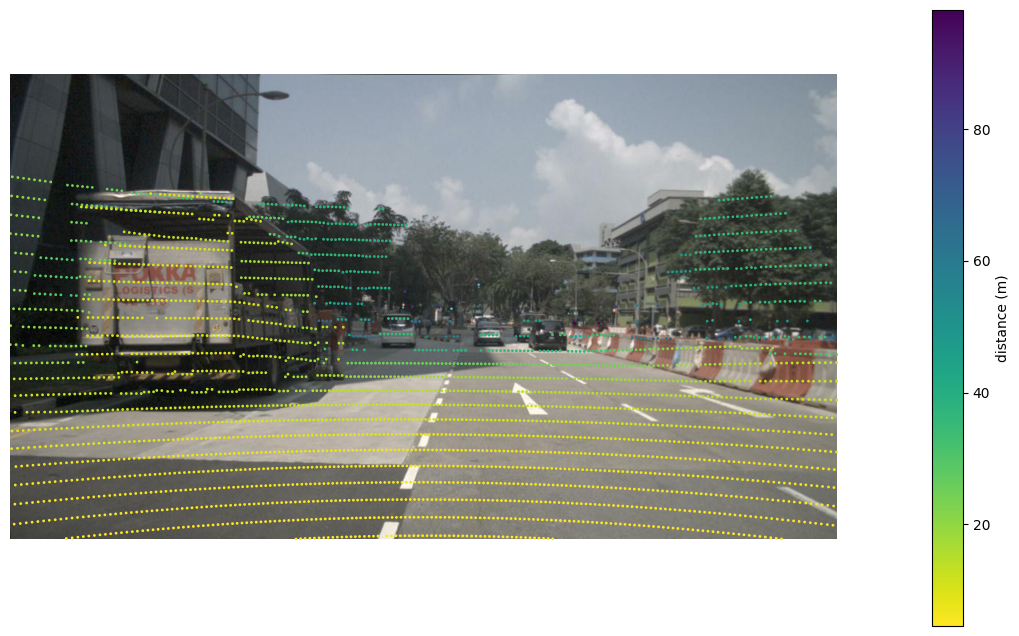

In [55]:
# Vérification : points lidar projetés sur l'image CAM_FRONT (couleur = distance)
import matplotlib.pyplot as plt
t = load_tables(DATAROOT, VERSION)
by = lambda tab: {r['token']: r for r in tab}
sensors, calibs, poses = by(t['sensor']), by(t['calibrated_sensor']), by(t['ego_pose'])
chan = lambda sd: sensors[calibs[sd['calibrated_sensor_token']]['sensor_token']]['channel']
tok = t['scene'][0]['first_sample_token']
lid = next(sd for sd in t['sample_data'] if sd['sample_token'] == tok and sd['is_key_frame'] and chan(sd) == 'LIDAR_TOP')
cam = next(sd for sd in t['sample_data'] if sd['sample_token'] == tok and sd['is_key_frame'] and chan(sd) == 'CAM_FRONT')

p = np.fromfile(os.path.join(DATAROOT, lid['filename']), dtype=np.float32).reshape(-1, 5)[:, :3]
T_lid = get_T(poses[lid['ego_pose_token']]) @ get_T(calibs[lid['calibrated_sensor_token']])
T_cam = get_T(poses[cam['ego_pose_token']]) @ get_T(calibs[cam['calibrated_sensor_token']])
pw = p @ T_lid[:3, :3].T + T_lid[:3, 3]
pc = (np.c_[pw, np.ones(len(pw))] @ np.linalg.inv(T_cam).T)[:, :3]
pc = pc[pc[:, 2] > 0.5]
uv = pc @ np.array(calibs[cam['calibrated_sensor_token']]['camera_intrinsic']).T
u, v = uv[:, 0] / uv[:, 2], uv[:, 1] / uv[:, 2]
img = plt.imread(os.path.join(DATAROOT, cam['filename']))
ok = (u >= 0) & (u < img.shape[1]) & (v >= 0) & (v < img.shape[0])

plt.figure(figsize=(14, 8)); plt.imshow(img)
plt.scatter(u[ok], v[ok], c=pc[ok, 2], s=1, cmap='viridis_r')
plt.colorbar(label='distance (m)'); plt.axis('off'); plt.show()

In [56]:
# !ns-train splatfacto --data /kaggle/working/nerf_data_tvt_lidar --output-dir /kaggle/working/outputs --max-num-iterations 18000 --viewer.quit-on-train-completion True --pipeline.model.num-downscales 2 nerfstudio-data

In [57]:
# # Expérience 4 : sans lidar (exp. 5, checkpoint 18 000) vs avec lidar (C, 18 000 itérations)
# import os, glob, torch, pandas as pd
# from pathlib import Path
# os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
# from nerfstudio.utils.eval_utils import eval_setup

# run_rand  = sorted(glob.glob('/kaggle/working/outputs/nerf_data_tvt/splatfacto/*/'))[-1]
# run_lidar = sorted(glob.glob('/kaggle/working/outputs/nerf_data_tvt_lidar/splatfacto/*/'))[-1]
# modeles = {
#     'Sans lidar (18k)': (run_rand,  run_rand  + 'nerfstudio_models/step-000018000.ckpt'),
#     'Avec lidar (18k)': (run_lidar, sorted(glob.glob(run_lidar + 'nerfstudio_models/*.ckpt'))[-1]),
# }

# def evaluate(run, ckpt, mode):
#     """Charge UN checkpoint précis et l'évalue sur 'val' ou 'test'."""
#     _, pipe, _, _ = eval_setup(Path(run) / 'config.yml', test_mode=mode)
#     sd = torch.load(ckpt, map_location='cpu', weights_only=False)
#     pipe.load_pipeline(sd['pipeline'], sd['step']); pipe.eval()
#     m = pipe.get_average_eval_image_metrics(step=sd['step'])
#     n = pipe.model.num_points
#     del pipe; torch.cuda.empty_cache()
#     return {'PSNR ↑': float(m['psnr']), 'SSIM ↑': float(m['ssim']), 'LPIPS ↓': float(m['lpips'])}, n

# for mode in ['val', 'test']:
#     lignes = {}
#     for label, (run, ckpt) in modeles.items():
#         metr, n = evaluate(run, ckpt, mode)
#         lignes[label] = {**metr, 'Gaussiennes': n}
#         print(f'{mode} | {label} | {os.path.basename(ckpt)}')
#     df = pd.DataFrame(lignes).T
#     df.loc['Écart (lidar − sans)'] = df.iloc[1] - df.iloc[0]
#     print(f'\n=== {mode.upper()} ===')
#     display(df.round(3))

### Résultat
| Jeu | Modèle | PSNR ↑ | SSIM ↑ | LPIPS ↓ | Gaussiennes |
|---|---|---|---|---|---|
| Validation | Sans lidar (18k) | 19.971 | 0.737 | 0.501 | 444 921 |
| Validation | Avec lidar (18k) | 19.924 | 0.746 | **0.455** | 512 224 |
| Test | Sans lidar (18k) | **20.905** | 0.750 | 0.457 | 444 921 |
| Test | Avec lidar (18k) | 20.103 | 0.751 | **0.447** | 512 224 |



### Analyse
- **LPIPS** : meilleur avec le lidar sur les deux jeux (−0,045 en validation, soit environ 9 % ; −0,010 en test).
  C'est le seul effet **cohérent** entre validation et test : le rendu avec lidar est perçu comme plus fidèle.
- **SSIM** : légèrement meilleur ou égal avec le lidar (+0,010 en validation, +0,001 en test).
- **PSNR** : identique en validation (−0,05 dB), mais −0,8 dB en test. Comme cette baisse n'apparaît pas en
  validation, elle est probablement en partie due au **hasard d'un entraînement unique** et à la petite taille du
  test (8 endroits de la rue), plutôt qu'à un vrai défaut du lidar.
- **Gaussiennes** : +15 % avec le lidar. Partir de points posés sur les surfaces semble pousser la densification à
  garder davantage de détails, ce qui va dans le sens du meilleur LPIPS.
- **Pourquoi le gain reste modeste** : à 18 000 itérations, il se pourrait que la densification ait eu le temps de redistribuer les
  gaussiennes de l'initialisation aléatoire. Le nuage lidar ne couvre pas le ciel, ni ce qui est au-delà de 60 m,
  et contient des traînées dues aux objets en mouvement.

### Conclusion
À 18 000 itérations, l'initialisation par le lidar **n'améliore pas la précision pixel par pixel** (PSNR), mais
améliore **la qualité perçue** (LPIPS) de façon cohérente sur validation et test.

### Questions
1. **Le lidar fait-il apprendre plus vite ?** Avec un bon point de départ, le modèle atteint peut-être son
   meilleur score avant 18 000 itérations. Pour le savoir, il faudrait entraîner C en sauvegardant des
   checkpoints, comme dans l'expérience 5, et comparer les deux courbes de validation.
2. **La différence est-elle réelle ou due à la chance ?** Deux entraînements identiques ne donnent jamais
   exactement le même score. Il faudrait relancer chaque version 2 ou 3 fois et comparer les moyennes.
3. **Un meilleur nuage lidar aiderait-il plus ?** Par exemple en retirant les points des voitures qui bougent,
   ou en utilisant tous les balayages lidar au lieu de 39.
4. **Le lidar aide-t-il plus quand on s'éloigne de la trajectoire ?** Les images de test sont proches de celles
   d'entraînement. En décalant la caméra d'un ou deux mètres sur le côté, une mauvaise géométrie se verrait
   beaucoup plus : c'est là que le lidar pourrait faire la différence.

## Expérience 6 : quel nuage lidar pour initialiser les gaussiennes ?
Trois nuages, une seule différence entre deux versions voisines :
- **L1** : balayages des 39 keyframes, objets mobiles gardés (le nuage de C) ;
- **L2** : balayages des 39 keyframes, **objets mobiles retirés** ;
- **L3** : **tous les balayages** (keyframes + sweeps), objets mobiles retirés.

L1 vs L2 → effet du retrait des objets mobiles. 

L2 vs L3 → effet de la densité.
Pour chaque version : courbes train / val (checkpoint toutes les 2 000 itérations, jusqu'à 18 000) et coût.

In [58]:
#  Cellule 1 : tables nuScenes et chaînes de captures
# --- Tables nuScenes et index utiles pour l'expérience 6 ---
import os, json, time
import numpy as np
import pandas as pd

t = load_tables(DATAROOT, VERSION)
by_token = lambda table: {r['token']: r for r in table}

sensors     = by_token(t['sensor'])
calibs      = by_token(t['calibrated_sensor'])
poses       = by_token(t['ego_pose'])
samples     = by_token(t['sample'])
sample_data = by_token(t['sample_data'])

def channel(sd):
    """Nom du capteur d'une capture (ex. 'LIDAR_TOP', 'CAM_FRONT')."""
    return sensors[calibs[sd['calibrated_sensor_token']]['sensor_token']]['channel']

def scene_chain(scene_idx, chan):
    """Toutes les captures (keyframes + sweeps) d'un capteur dans une scène, dans l'ordre du temps."""
    first_sample = t['scene'][scene_idx]['first_sample_token']
    sd = next(s for s in t['sample_data']
              if s['sample_token'] == first_sample and s['is_key_frame'] and channel(s) == chan)
    chain = []
    while sd:                       # on suit la chaîne 'next' jusqu'à la fin de la scène
        chain.append(sd)
        sd = sample_data.get(sd['next'])
    return chain

lidar_chain = scene_chain(0, 'LIDAR_TOP')
cam_chain   = scene_chain(0, 'CAM_FRONT')
print(f"LIDAR_TOP : {len(lidar_chain)} balayages, dont {sum(s['is_key_frame'] for s in lidar_chain)} keyframes")
print(f"CAM_FRONT : {len(cam_chain)} images")

LIDAR_TOP : 382 balayages, dont 39 keyframes
CAM_FRONT : 224 images


In [59]:
#   Cellule 2 : géométrie (lidar → monde, monde → image)
# --- Fonctions géométriques ---

def lidar_to_world(sd, r_min=3.0, r_max=60.0):
    """Lit un balayage lidar et renvoie ses points dans le repère MONDE, tableau (N, 3)."""
    pts = np.fromfile(os.path.join(DATAROOT, sd['filename']), dtype=np.float32).reshape(-1, 5)[:, :3]
    # On retire la carrosserie de la voiture (< 3 m) et le très lointain (> 60 m)
    dist = np.linalg.norm(pts[:, :2], axis=1)
    pts = pts[(dist > r_min) & (dist < r_max)]
    # lidar → voiture (calibration) → monde (pose de la voiture À L'INSTANT du balayage)
    T = get_T(poses[sd['ego_pose_token']]) @ get_T(calibs[sd['calibrated_sensor_token']])
    return pts @ T[:3, :3].T + T[:3, 3]


def project_to_camera(pw, cam_sd):
    """Projette des points monde dans une image caméra, en convention OpenCV (celle de nuScenes).
    Renvoie : indices des points visibles, et leurs pixels (u, v)."""
    T_cam = get_T(poses[cam_sd['ego_pose_token']]) @ get_T(calibs[cam_sd['calibrated_sensor_token']])
    pc = (np.c_[pw, np.ones(len(pw))] @ np.linalg.inv(T_cam).T)[:, :3]   # monde → caméra
    K = np.array(calibs[cam_sd['calibrated_sensor_token']]['camera_intrinsic'])

    front = np.flatnonzero(pc[:, 2] > 0.5)          # devant la caméra (z > 0,5 m)
    uv = pc[front] @ K.T                             # projection : u = fx·x/z + cx, v = fy·y/z + cy
    u = (uv[:, 0] / uv[:, 2]).astype(int)
    v = (uv[:, 1] / uv[:, 2]).astype(int)
    inside = (u >= 0) & (u < cam_sd['width']) & (v >= 0) & (v < cam_sd['height'])
    return front[inside], u[inside], v[inside]


cam_times = np.array([s['timestamp'] for s in cam_chain])

def nearest_camera(timestamp):
    """Image CAM_FRONT la plus proche dans le temps (sert à colorier les points d'un balayage)."""
    return cam_chain[int(np.argmin(np.abs(cam_times - timestamp)))]

In [60]:
# Cellule 3 : boîtes des objets mobiles (annotées aux keyframes, interpolées entre elles)
# --- Objets mobiles : boîtes 3D annotées dans nuScenes ---
attributes  = {a['token']: a['name'] for a in json.load(open(f'{DATAROOT}/{VERSION}/attribute.json'))}
annotations = json.load(open(f'{DATAROOT}/{VERSION}/sample_annotation.json'))

def is_moving(ann):
    """Un objet est 'mobile' si l'un de ses attributs se termine par '.moving'
    (vehicle.moving, pedestrian.moving, ...). Les voitures garées sont gardées."""
    return any(attributes[a].endswith('.moving') for a in ann['attribute_tokens'])

# Boîtes mobiles par keyframe : {sample_token: {instance_token: annotation}}
moving_by_sample = {}
for ann in annotations:
    if is_moving(ann):
        moving_by_sample.setdefault(ann['sample_token'], {})[ann['instance_token']] = ann

key_samples = [samples[s['sample_token']] for s in lidar_chain if s['is_key_frame']]
key_times   = np.array([s['timestamp'] for s in key_samples])


def slerp(q0, q1, a):
    """Interpolation sphérique entre deux quaternions [w, x, y, z], a dans [0, 1]."""
    q0, q1 = np.array(q0, float), np.array(q1, float)
    if np.dot(q0, q1) < 0:                     # prendre le plus court chemin
        q1 = -q1
    d = np.clip(np.dot(q0, q1), -1, 1)
    if d > 0.9995:                             # quasi identiques : interpolation linéaire suffit
        q = q0 + a * (q1 - q0)
    else:
        th = np.arccos(d)
        q = (np.sin((1 - a) * th) * q0 + np.sin(a * th) * q1) / np.sin(th)
    return q / np.linalg.norm(q)


def moving_boxes_at(timestamp):
    """Boîtes (centre, quaternion, taille) des objets mobiles à un instant donné.
    Aux keyframes : boîtes annotées. Entre deux keyframes : interpolées
    (position linéaire, rotation sphérique). Objet vu à une seule keyframe : sa boîte telle quelle."""
    i = np.searchsorted(key_times, timestamp)
    prev = key_samples[max(i - 1, 0)]
    nxt  = key_samples[min(i, len(key_samples) - 1)]
    span = nxt['timestamp'] - prev['timestamp']
    a = 0.0 if span == 0 else float(np.clip((timestamp - prev['timestamp']) / span, 0, 1))

    A = moving_by_sample.get(prev['token'], {})
    B = moving_by_sample.get(nxt['token'], {})
    boxes = []
    for inst in set(A) | set(B):
        if inst in A and inst in B:
            center = (1 - a) * np.array(A[inst]['translation']) + a * np.array(B[inst]['translation'])
            quat   = slerp(A[inst]['rotation'], B[inst]['rotation'], a)
            size   = A[inst]['size']
        else:
            ann = A.get(inst) or B.get(inst)
            center, quat, size = np.array(ann['translation']), ann['rotation'], ann['size']
        boxes.append((center, quat, size))
    return boxes


def outside_boxes(pw, boxes, margin=0.3):
    """Masque des points SITUÉS HORS de toutes les boîtes (agrandies de `margin` mètres)."""
    keep = np.ones(len(pw), bool)
    for center, quat, (w, l, h) in boxes:        # taille nuScenes : largeur, longueur, hauteur
        R = quat_to_rotmat(quat)
        local = (pw - center) @ R                  # coordonnées dans le repère de la boîte
        inside = ((np.abs(local[:, 0]) <= l / 2 + margin) &
                  (np.abs(local[:, 1]) <= w / 2 + margin) &
                  (np.abs(local[:, 2]) <= h / 2 + margin))
        keep &= ~inside
    return keep

In [61]:

# --- Construction d'un nuage lidar fusionné et colorié ---
import open3d as o3d
from PIL import Image

def build_lidar_cloud(out_ply, use_sweeps, remove_moving, voxel=0.15):
    """Fusionne des balayages lidar dans le repère monde, retire (ou non) les objets mobiles,
    colorie les points avec CAM_FRONT, sous-échantillonne, et enregistre un .ply.
    Renvoie des statistiques de coût."""
    t0 = time.time()
    sweeps = lidar_chain if use_sweeps else [s for s in lidar_chain if s['is_key_frame']]

    pts_all, col_all = [], []
    n_raw, n_removed = 0, 0
    for sd in sweeps:
        pw = lidar_to_world(sd)
        n_raw += len(pw)

        if remove_moving:                                     # retrait des objets mobiles
            keep = outside_boxes(pw, moving_boxes_at(sd['timestamp']))
            n_removed += int((~keep).sum())
            pw = pw[keep]

        cam = nearest_camera(sd['timestamp'])                 # image la plus proche dans le temps
        idx, u, v = project_to_camera(pw, cam)                # points vus par CAM_FRONT
        img = np.asarray(Image.open(os.path.join(DATAROOT, cam['filename'])).convert('RGB'))
        pts_all.append(pw[idx])
        col_all.append(img[v, u])                              # couleur du pixel où tombe le point

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(np.concatenate(pts_all))
    pcd.colors = o3d.utility.Vector3dVector(np.concatenate(col_all) / 255.0)
    n_before = len(pcd.points)
    pcd = pcd.voxel_down_sample(voxel)                         # un point par cube de 15 cm
    o3d.io.write_point_cloud(out_ply, pcd)

    return {'balayages': len(sweeps), 'points bruts': n_raw, 'points mobiles retirés': n_removed,
            'points vus par la caméra': n_before, 'points finaux (après voxel)': len(pcd.points),
            'temps (s)': round(time.time() - t0, 1)}

In [62]:
# les 3 nuages et leurs coûts
# --- Construction de L1, L2, L3 ---
versions = {
    'L1': dict(use_sweeps=False, remove_moving=False),   # = nuage de C
    'L2': dict(use_sweeps=False, remove_moving=True),
    'L3': dict(use_sweeps=True,  remove_moving=True),
}

os.makedirs('/kaggle/working/lidar_clouds', exist_ok=True)
stats = {}
for name, cfg in versions.items():
    stats[name] = build_lidar_cloud(f'/kaggle/working/lidar_clouds/{name}.ply', **cfg)
    print(name, 'terminé')

df_stats = pd.DataFrame(stats).T
df_stats.to_csv('/kaggle/working/lidar_clouds/stats.csv')     # garder les chiffres en fichier
display(df_stats)

L1 terminé
L2 terminé
L3 terminé


,balayages,points bruts,points mobiles retirés,points vus par la caméra,points finaux (après voxel),temps (s)
L1,39.0,978602.0,0.0,114182.0,63536.0,0.5
L2,39.0,978602.0,16592.0,103351.0,58141.0,1.0
L3,382.0,9588581.0,160875.0,989563.0,240207.0,10.3


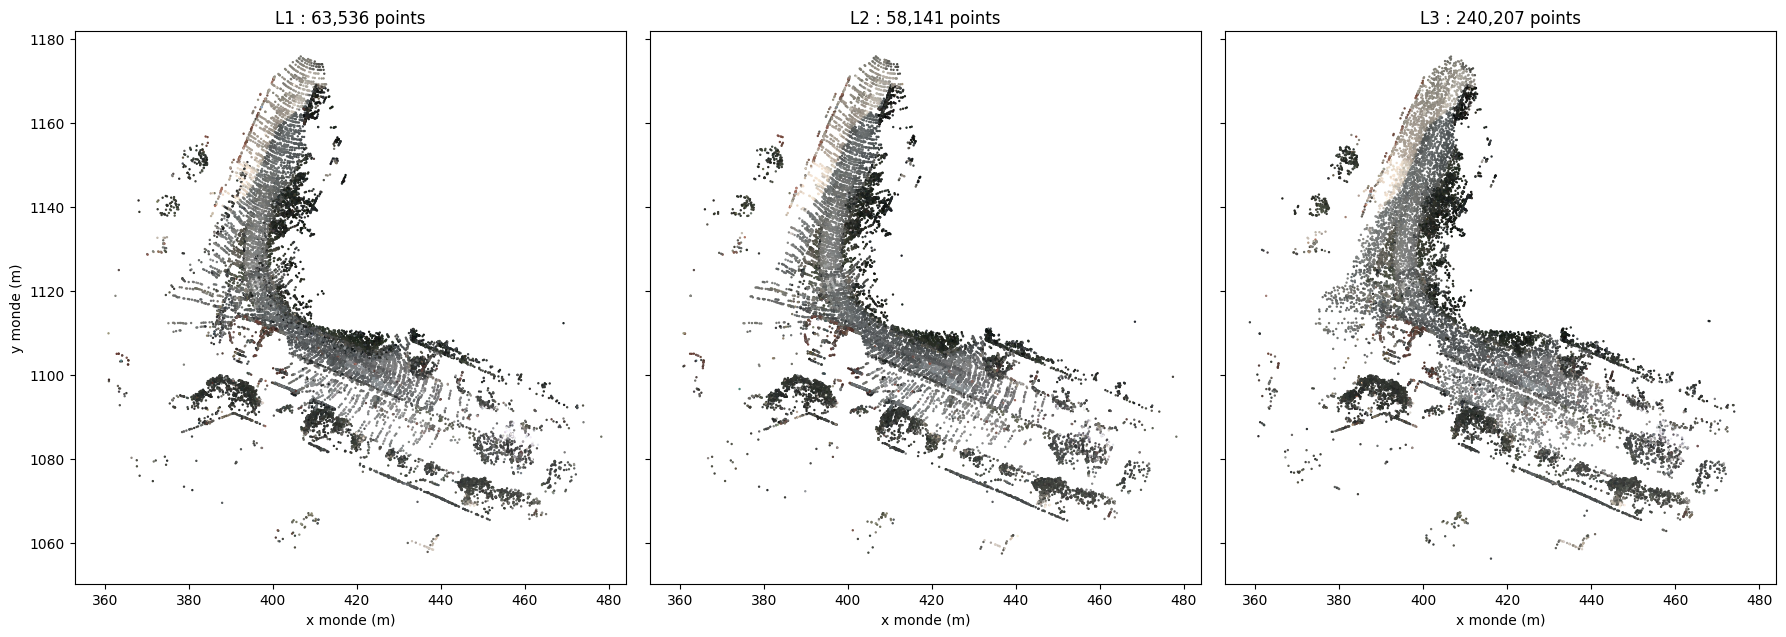

In [63]:
# verification visuelle (vue du dessus)
# --- Les trois nuages vus du dessus (20 000 points tirés au hasard chacun) ---
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
rng = np.random.default_rng(0)
for ax, name in zip(axes, versions):
    pcd = o3d.io.read_point_cloud(f'/kaggle/working/lidar_clouds/{name}.ply')
    P, C = np.asarray(pcd.points), np.asarray(pcd.colors)
    sel = rng.choice(len(P), size=min(20000, len(P)), replace=False)
    ax.scatter(P[sel, 0], P[sel, 1], c=C[sel], s=0.5)
    ax.set_title(f'{name} : {len(P):,} points')
    ax.set_aspect('equal'); ax.set_xlabel('x monde (m)')
axes[0].set_ylabel('y monde (m)')
plt.tight_layout(); plt.show()

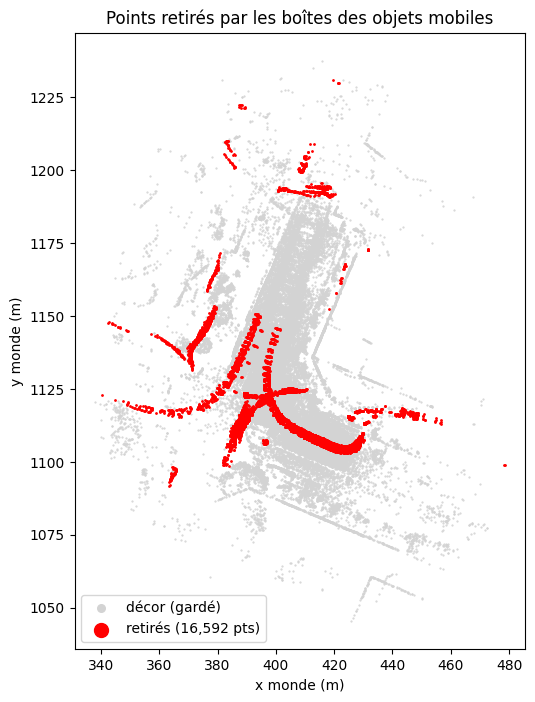

In [64]:
# --- Vérification : où sont les points retirés (objets mobiles) ? ---
# On refait le parcours des 39 keyframes, mais on GARDE les points supprimés pour les afficher.
removed = []
kept = []
for sd in lidar_chain:
    if not sd['is_key_frame']:
        continue
    pw = lidar_to_world(sd)
    keep = outside_boxes(pw, moving_boxes_at(sd['timestamp']))
    removed.append(pw[~keep])     # points dans une boîte d'objet mobile
    kept.append(pw[keep][::20])   # 1 point sur 20 suffit pour le décor

removed = np.concatenate(removed)
kept = np.concatenate(kept)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(kept[:, 0], kept[:, 1], s=0.3, c='lightgray', label='décor (gardé)')
ax.scatter(removed[:, 0], removed[:, 1], s=1, c='red', label=f'retirés ({len(removed):,} pts)')
ax.set_aspect('equal')
ax.legend(markerscale=10)
ax.set_title('Points retirés par les boîtes des objets mobiles')
ax.set_xlabel('x monde (m)')
ax.set_ylabel('y monde (m)')
plt.show()

In [65]:
# --- Un transforms.json par nuage, dans le dossier nerf_data_tvt ---
# On ne copie pas les images : les trois fichiers pointent vers les mêmes images
# et les mêmes découpages train / val / test. Seul le nuage d'initialisation change.
import shutil

DATA = '/kaggle/working/nerf_data_tvt'
base = json.load(open(f'{DATA}/transforms.json'))

for name in ['L1', 'L2', 'L3']:
    # 1) Copier le nuage à côté des images (nerfstudio le cherche relativement au dossier)
    shutil.copy(f'/kaggle/working/lidar_clouds/{name}.ply', f'{DATA}/{name}.ply')

    # 2) Même contenu que transforms.json, mais avec le nuage lidar en initialisation
    tj = dict(base)
    tj['ply_file_path'] = f'{name}.ply'
    json.dump(tj, open(f'{DATA}/transforms_{name}.json', 'w'), indent=2)

    print(name, ':', len(tj['train_filenames']), 'train |',
          len(tj['val_filenames']), 'val |', len(tj['test_filenames']), 'test')

L1 : 125 train | 47 val | 52 test
L2 : 125 train | 47 val | 52 test
L3 : 125 train | 47 val | 52 test


In [66]:
# # --- Lancer un entraînement en arrière-plan, sur un GPU choisi ---
# import subprocess

# def launch(name, gpu):
#     """Entraîne splatfacto 18 000 itérations avec le nuage `name`, sur le GPU `gpu`.
#     Checkpoint toutes les 2 000 itérations (tous gardés).
#     Le temps d'entraînement est écrit dans logs/exp6_{name}_seconds.txt."""
#     os.makedirs('/kaggle/working/logs', exist_ok=True)
#     log = f'/kaggle/working/logs/exp6_{name}'

#     ns_train = (
#         f'ns-train splatfacto '
#         f'--data {DATA}/transforms_{name}.json '
#         f'--experiment-name exp6_{name} '
#         f'--max-num-iterations 18000 '
#         f'--steps-per-save 2000 '
#         f'--save-only-latest-checkpoint False '
#         f'--viewer.quit-on-train-completion True'
#     )
#     # Petit script bash : chronomètre autour de ns-train
#     script = f"""
#     start=$(date +%s)
#     {ns_train}
#     end=$(date +%s)
#     echo $((end - start)) > {log}_seconds.txt
#     """
#     env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu))   # un run = un GPU
#     return subprocess.Popen(['bash', '-c', script], env=env,
#                             stdout=open(f'{log}.log', 'w'), stderr=subprocess.STDOUT)

In [67]:
# # --- Kaggle donne 2 GPU T4 : on lance L1 sur le GPU 0 et L2 sur le GPU 1 ---
# procs = {
#     'L1': launch('L1', gpu=0),
#     'L2': launch('L2', gpu=1),
# }

In [68]:
# # --- Lancer L3 seulement quand L1 est terminé (état 0 dans la cellule 10) ---
# procs['L3'] = launch('L3', gpu=0)

In [69]:
# # --- État des runs : None = en cours, 0 = fini sans erreur, autre = erreur ---
# for name, p in procs.items():
#     print(f'=== {name} : état {p.poll()} ===')
#     lines = open(f'/kaggle/working/logs/exp6_{name}.log').read().splitlines()
#     print('\n'.join(lines[-3:]))   # 3 dernières lignes du log

In [70]:
# --- Temps total d'entraînement (secondes), écrit par le script bash ---
for name in ['L1', 'L2', 'L3']:
    s = int(open(f'/kaggle/working/logs/exp6_{name}_seconds.txt').read())
    print(f'{name} : {s // 60} min {s % 60} s')

L1 : 19 min 59 s
L2 : 19 min 42 s
L3 : 19 min 7 s


In [71]:
# --- Dossiers des trois runs et liste de leurs checkpoints ---
import glob, torch
from pathlib import Path

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'   # sinon torch.load refuse les checkpoints
from nerfstudio.utils.eval_utils import eval_setup

def find_run(name):
    """Dernier run de l'expérience exp6_{name} (dossier contenant config.yml)."""
    runs = sorted(glob.glob(f'/kaggle/working/outputs/exp6_{name}/splatfacto/*/'))
    return Path(runs[-1])

for name in ['L1', 'L2', 'L3']:
    ckpts = sorted(glob.glob(str(find_run(name) / 'nerfstudio_models/step-*.ckpt')))
    print(name, ':', [Path(c).stem for c in ckpts])

In [72]:
# --- Métriques moyennes sur les 125 images de train ---
# nerfstudio ne sait évaluer que val ou test ; pour train, on boucle nous-mêmes.
def train_metrics(pipeline):
    pipeline.eval()      # mode évaluation : rendu seul, sans densification
                         # (la mesure sur val remet le modèle en mode entraînement à la fin)
    dm, model = pipeline.datamanager, pipeline.model
    cameras = dm.train_dataset.cameras
    scores = []
    with torch.no_grad():
        for i in range(len(cameras)):
            camera = cameras[i:i + 1].to(model.device)
            outputs = model.get_outputs_for_camera(camera)       # rendu de la vue i
            batch = {'image': dm.cached_train[i]['image']}       # vraie image i
            metrics, _ = model.get_image_metrics_and_images(outputs, batch)
            scores.append(metrics)
    return {k: float(np.mean([s[k] for s in scores])) for k in ['psnr', 'ssim', 'lpips']}

In [73]:
# --- Pour un run : charger chaque checkpoint et mesurer train + val ---
def curves_for(name):
    run = find_run(name)
    _, pipeline, _, _ = eval_setup(run / 'config.yml', test_mode='val')
    rows = []
    for ckpt in sorted(glob.glob(str(run / 'nerfstudio_models/step-*.ckpt'))):
        sd = torch.load(ckpt, map_location='cpu')
        pipeline.load_pipeline(sd['pipeline'], sd['step'])      # charge les gaussiennes de ce checkpoint
        pipeline.eval()

        val = pipeline.get_average_eval_image_metrics(step=sd['step'])
        train = train_metrics(pipeline)
        rows.append({
            'step': sd['step'],
            'n_gaussians': int(pipeline.model.means.shape[0]),
            **{f'train_{k}': v for k, v in train.items()},
            **{f'val_{k}': float(val[k]) for k in ['psnr', 'ssim', 'lpips']},
        })
        print(name, sd['step'], f"val PSNR {rows[-1]['val_psnr']:.2f}")

    del pipeline
    torch.cuda.empty_cache()     # libérer le GPU avant le run suivant
    return rows

In [74]:
# # --- Calcul pour L1, L2, L3 (quelques minutes par run) ---
# curves = {name: curves_for(name) for name in ['L1', 'L2', 'L3']}
# json.dump(curves, open('/kaggle/working/exp6_curves.json', 'w'), indent=2)

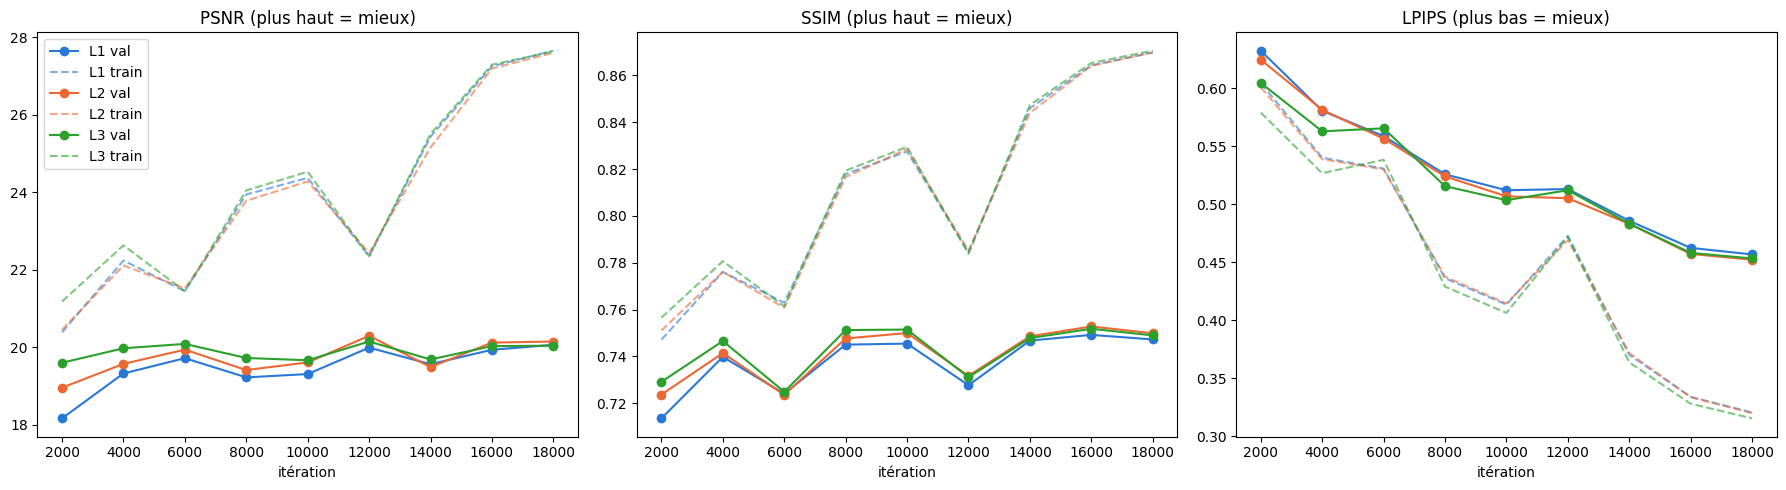

In [75]:
# --- Graphiques de l'expérience 6, relus depuis le fichier (aucun recalcul) ---
import json
import matplotlib.pyplot as plt

curves = json.load(open('/kaggle/working/exp6_curves.json'))

# Une couleur par nuage ; trait plein = val, pointillés = train
colors = {'L1': '#2a78d6', 'L2': '#eb6834', 'L3': '#2ca02c'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, ['psnr', 'ssim', 'lpips']):
    for name, rows in curves.items():
        steps = [r['step'] for r in rows]
        ax.plot(steps, [r[f'val_{metric}'] for r in rows], '-o', c=colors[name], label=f'{name} val')
        ax.plot(steps, [r[f'train_{metric}'] for r in rows], '--', c=colors[name], alpha=0.6, label=f'{name} train')
    ax.set_title(metric.upper() + (' (plus bas = mieux)' if metric == 'lpips' else ' (plus haut = mieux)'))
    ax.set_xlabel('itération')
axes[0].legend()
plt.tight_layout()
plt.savefig('/kaggle/working/exp6_curves.png', dpi=120)
plt.show()

## Expériance 7 : test sur les nouvelles vues issues de CAM_Front_left

### Analyse
1. **Un meilleur nuage aide au début.** À 2 000 itérations, retirer les objets mobiles fait gagner ≈ 0,8 dB (L1 → L2), et densifier encore ≈ 0,6 dB (L2 → L3).
2. **L'avantage disparaît vers 6 000 itérations.** À 18 000, les écarts sont inférieurs à 0,2 dB. Avec une seule exécution par nuage, on ne peut pas les distinguer du bruit.
3. **Le coût ne change presque pas.** L3 part avec 4× plus de points mais met le même temps : la densification ajuste ensuite le nombre de gaussiennes selon les images.
4. **Fort surapprentissage.** À 18k, PSNR train ≈ 27,6 contre ≈ 20 en val : le modèle mémorise les images d'entraînement. La val ne progresse plus que lentement après ≈ 4 000 itérations (≈ +0,5 dB jusqu'à 18k).
5. **LPIPS val baisse jusqu'au bout** (≈ 0,63 → 0,45) : les images deviennent plus nettes même quand le PSNR ne bouge plus.
6. **Les creux à 6 000 et 12 000 sont un artefact de mesure.** Toutes les 3 000 itérations (`reset_alpha_every 30 × refine_every 100`), splatfacto plafonne l'opacité de toutes les gaussiennes. Celles qui ne regagnent pas d'opacité sont ensuite supprimées : c'est un « grand ménage » contre les gaussiennes inutiles. Juste après, le modèle est temporairement moins bon. Ce ménage s'arrête à 15 000 (`stop_split_at`). Les checkpoints à 6 000 et 12 000 tombent pile dessus. L'effet est fort sur les courbes **train**, faible sur le PSNR **val**.

### Conclusion
- Un **meilleur nuage lidar** (objets mobiles retirés, sweeps ajoutés) **accélère le début** de l'apprentissage, mais **ne change pas le résultat final**.
- Retirer les objets mobiles et ajouter les sweeps **ne coûte presque rien** : on garde L3 par défaut.
- Ce qui limite le modèle aujourd'hui, ce n'est pas l'initialisation : c'est le **surapprentissage**.

### ⚠️ Note sur l'expérience 5
L'expérience 5 sauvegardait toutes les 3 000 itérations. Avant 15 000, chaque checkpoint tombait pile sur un reset d'opacité (le « ménage »).
- **Courbe train : faussée.** Le saut entre 12k et 15k n'est pas un apprentissage soudain : 15k est le premier point mesuré hors reset. Le surapprentissage commençait donc plus tôt que la courbe ne le montrait.
- **Courbe val : peu touchée.** Dans l'expérience 6, le PSNR val ne chute pas aux points de reset. La conclusion « la val plafonne vers 18k » reste valable.

**Leçon**:

On fait du l’early stopping (arrêt précoce), qui consiste à choisir le modèle sur la validation. Concrètement, on retient :

Un plafond : 18 000 itérations. Au-delà, la val ne bouge plus (l’expérience 5 l’a montré jusqu’à 30k). Inutile de dépenser du GPU après.
Des sauvegardes régulières, mais pas sur les resets. Les resets tombent à 3k, 6k, 9k et 12k. Avec --steps-per-save 2000, on tombe encore dessus à 6k et 12k. --steps-per-save 2500 les évite tous : 2 500, 5 000, 7 500, 10 000, 12 500, 15 000 (15 000 n’est plus un reset).
On garde le checkpoint qui a le meilleur score val. Si plusieurs sont à égalité, à 0,1 dB près, on prend le plus tôt : il a moins surappris.

### Questions
1. Comment se comportent-ils sur de **vraies nouvelles vues** (CAM_FRONT_LEFT) ?
2. Comment réduire le surapprentissage : plus de vues, d'autres caméras, régularisation ?

## Expérience 7 : apprendre la scène avec les 3 caméras avant
Entraînement sur CAM_FRONT_LEFT + CAM_FRONT + CAM_FRONT_RIGHT, initialisé avec un nuage lidar L3 qui couvre les 3 champs de vision.
Plan : 1) entraîner  2) valider (courbes, choix du checkpoint sur val)  3) décaler les caméras de test  4) décaler ailleurs et visualiser.

In [76]:
# --- Imports nécessaires à l'expérience 7 (à relancer après chaque redémarrage) ---
import open3d as o3d
import matplotlib.pyplot as plt
from PIL import Image
import shutil, subprocess

rng = np.random.default_rng(0)

In [77]:
# --- Images (keyframes + sweeps) des 3 caméras avant ---
CAMS = ['CAM_FRONT_LEFT', 'CAM_FRONT', 'CAM_FRONT_RIGHT']
chains = {cam: scene_chain(0, cam) for cam in CAMS}

for cam, chain in chains.items():
    print(f'{cam:16s} {len(chain)} images, dont {sum(s["is_key_frame"] for s in chain)} keyframes')

CAM_FRONT_LEFT   224 images, dont 39 keyframes
CAM_FRONT        224 images, dont 39 keyframes
CAM_FRONT_RIGHT  217 images, dont 39 keyframes


In [78]:
# --- Même règle que nerf_data_tvt, appliquée à chaque caméra ---
# Keyframe n°i : test si i % 5 == 2, val si i % 5 == 4, sinon train.
# Une image sweep prend le groupe de sa keyframe la plus proche, si elle est à moins de 0,25 s ; sinon train.
def split_of_chain(chain):
    keys = [s for s in chain if s['is_key_frame']]
    key_times = np.array([s['timestamp'] for s in keys])
    key_label = ['test' if i % 5 == 2 else 'val' if i % 5 == 4 else 'train' for i in range(len(keys))]

    labels = []
    for s in chain:
        j = int(np.argmin(np.abs(key_times - s['timestamp'])))      # keyframe la plus proche
        close = abs(key_times[j] - s['timestamp']) <= 0.25e6         # timestamps en microsecondes
        labels.append(key_label[j] if (s['is_key_frame'] or close) else 'train')
    return labels

In [79]:
# --- Dossier nerf_data_3cams : images + transforms.json (paramètres internes PAR image) ---
OUT3 = '/kaggle/working/nerf_data_3cams'
os.makedirs(f'{OUT3}/images', exist_ok=True)

frames = []
splits = {'train': [], 'val': [], 'test': []}
for cam, chain in chains.items():
    for s, label in zip(chain, split_of_chain(chain)):
        name = f"images/{s['token']}.jpg"
        shutil.copy(os.path.join(DATAROOT, s['filename']), f'{OUT3}/{name}')

        # Pose caméra -> monde, convertie en OpenGL (comme avant)
        c2w = get_T(poses[s['ego_pose_token']]) @ get_T(calibs[s['calibrated_sensor_token']]) @ OPENCV_TO_OPENGL
        K = calibs[s['calibrated_sensor_token']]['camera_intrinsic']
        frames.append({
            'file_path': name,
            'transform_matrix': c2w.tolist(),
            # chaque caméra a sa propre focale et son propre centre
            'fl_x': K[0][0], 'fl_y': K[1][1], 'cx': K[0][2], 'cy': K[1][2],
            'w': s['width'], 'h': s['height'],
        })
        splits[label].append(name)

tj3 = {'camera_model': 'OPENCV', 'frames': frames,
       'train_filenames': splits['train'], 'val_filenames': splits['val'], 'test_filenames': splits['test']}
json.dump(tj3, open(f'{OUT3}/transforms.json', 'w'), indent=2)
print({k: len(v) for k, v in splits.items()})

{'train': 400, 'val': 122, 'test': 143}


In [80]:
# --- Même recette que L3, mais un point est gardé s'il est vu par AU MOINS UNE des 3 caméras ---
cam_times = {cam: np.array([s['timestamp'] for s in chain]) for cam, chain in chains.items()}

def build_cloud_3cams(out_ply, voxel=0.15):
    t0 = time.time()
    pts_all, col_all = [], []
    for sd in lidar_chain:                                       # les 382 balayages
        pw = lidar_to_world(sd)
        pw = pw[outside_boxes(pw, moving_boxes_at(sd['timestamp']))]   # objets mobiles retirés

        for cam in CAMS:                                         # chaque caméra colorie ce qu'elle voit
            cam_sd = chains[cam][int(np.argmin(np.abs(cam_times[cam] - sd['timestamp'])))]
            idx, u, v = project_to_camera(pw, cam_sd)
            img = np.asarray(Image.open(os.path.join(DATAROOT, cam_sd['filename'])).convert('RGB'))
            pts_all.append(pw[idx])
            col_all.append(img[v, u])

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(np.concatenate(pts_all))
    pcd.colors = o3d.utility.Vector3dVector(np.concatenate(col_all) / 255.0)
    pcd = pcd.voxel_down_sample(voxel)        # fusionne aussi les points vus par deux caméras
    o3d.io.write_point_cloud(out_ply, pcd)
    print(f'{len(pcd.points):,} points, {time.time() - t0:.0f} s')

build_cloud_3cams(f'{OUT3}/L3_3cams.ply')
tj3['ply_file_path'] = 'L3_3cams.ply'
json.dump(tj3, open(f'{OUT3}/transforms.json', 'w'), indent=2)

511,108 points, 18 s


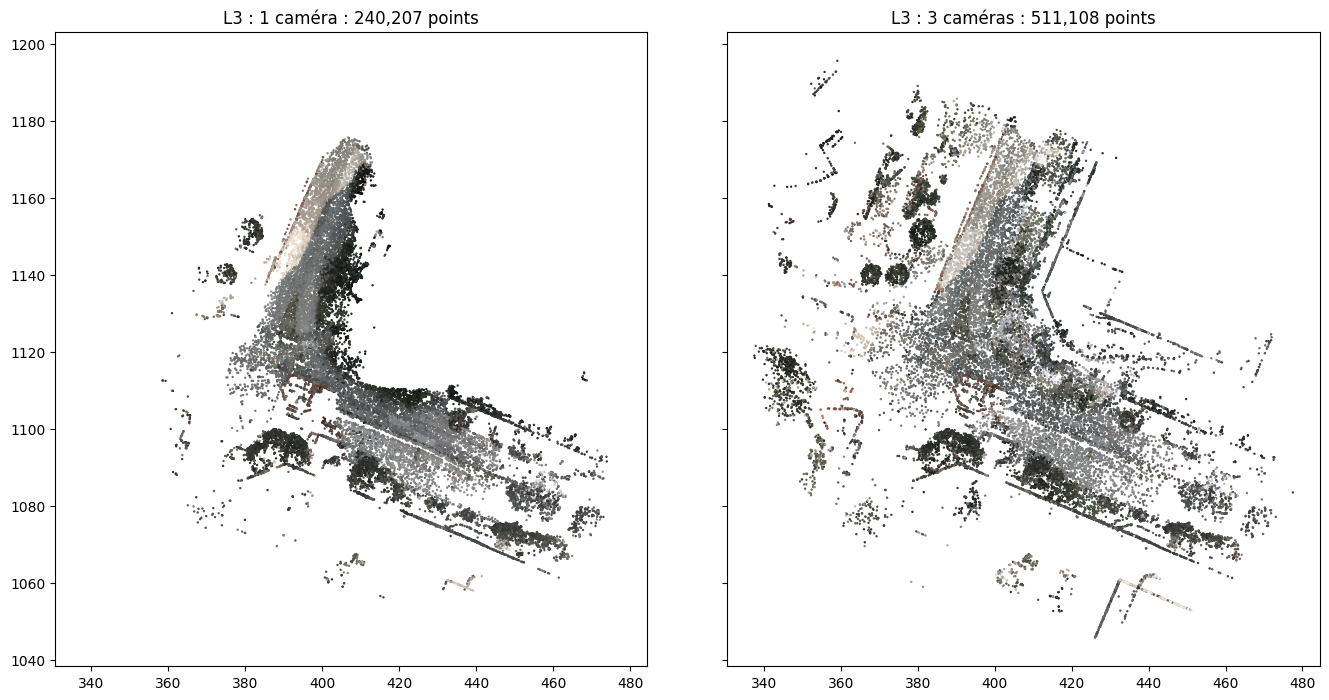

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, (title, path) in zip(axes, [('L3 : 1 caméra', '/kaggle/working/lidar_clouds/L3.ply'),
                                     ('L3 : 3 caméras', f'{OUT3}/L3_3cams.ply')]):
    pcd = o3d.io.read_point_cloud(path)
    P, C = np.asarray(pcd.points), np.asarray(pcd.colors)
    sel = rng.choice(len(P), size=min(30000, len(P)), replace=False)
    ax.scatter(P[sel, 0], P[sel, 1], c=C[sel], s=0.5)
    ax.set_title(f'{title} : {len(P):,} points'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

In [82]:
# # --- 18 000 itérations, checkpoint toutes les 2 500 (jamais sur un reset), images stockées en uint8 ---
# script = f"""
# start=$(date +%s)
# ns-train splatfacto \
#   --data {OUT3} \
#   --experiment-name exp7_3cams \
#   --max-num-iterations 18000 \
#   --steps-per-save 2500 \
#   --save-only-latest-checkpoint False \
#   --pipeline.datamanager.cache-images-type uint8 \
#   --viewer.quit-on-train-completion True
# end=$(date +%s)
# echo $((end - start)) > /kaggle/working/logs/exp7_seconds.txt
# """
# proc7 = subprocess.Popen(['bash', '-c', script], env=dict(os.environ, CUDA_VISIBLE_DEVICES='0'),
#                          stdout=open('/kaggle/working/logs/exp7.log', 'w'), stderr=subprocess.STDOUT)

In [83]:
# --- Run de l'expérience 7 ---
import os, glob, json, torch
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
from nerfstudio.utils.eval_utils import eval_setup

run7 = Path(sorted(glob.glob('/kaggle/working/outputs/exp7_3cams/splatfacto/*/'))[-1])
ckpts7 = sorted(glob.glob(str(run7 / 'nerfstudio_models/step-*.ckpt')))
print(run7.name, '|', len(ckpts7), 'checkpoints')

/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning:

`torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.

/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning:

`torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.



2026-10-21_160447 | 8 checkpoints


In [84]:
# --- Rendu + notes de chaque image d'un groupe (train ou val) ---
# Les images ont été nommées par leur token nuScenes : on retrouve ainsi leur caméra.
def per_image_metrics(pipeline, dataset, cached):
    pipeline.eval()                                   # rendu seul, sans densification
    model = pipeline.model
    rows = []
    with torch.no_grad():
        for i in range(len(dataset)):
            camera = dataset.cameras[i:i + 1].to(model.device)
            outputs = model.get_outputs_for_camera(camera)
            metrics, _ = model.get_image_metrics_and_images(outputs, {'image': cached[i]['image']})
            token = Path(dataset.image_filenames[i]).stem
            rows.append({'camera': channel(sample_data[token]),
                         'psnr': float(metrics['psnr']),
                         'ssim': float(metrics['ssim']),
                         'lpips': float(metrics['lpips'])})
    return pd.DataFrame(rows)

In [85]:
# # --- Pour chaque checkpoint : moyenne train, et moyenne val par caméra ---
# _, pipe7, _, _ = eval_setup(run7 / 'config.yml', test_mode='val')
# dm = pipe7.datamanager

# curves7 = []
# for ckpt in ckpts7:
#     sd = torch.load(ckpt, map_location='cpu')
#     pipe7.load_pipeline(sd['pipeline'], sd['step'])

#     tr = per_image_metrics(pipe7, dm.train_dataset, dm.cached_train)
#     va = per_image_metrics(pipe7, dm.eval_dataset, dm.cached_eval)

#     row = {'step': sd['step'], 'n_gaussians': int(pipe7.model.means.shape[0])}
#     for m in ['psnr', 'ssim', 'lpips']:
#         row[f'train_{m}'] = tr[m].mean()
#         row[f'val_{m}'] = va[m].mean()                                   # les 3 caméras
#         for cam, v in va.groupby('camera')[m].mean().items():            # caméra par caméra
#             row[f'val_{m}_{cam}'] = v
#     curves7.append(row)
#     print(sd['step'], f"val PSNR {row['val_psnr']:.2f} | LPIPS {row['val_lpips']:.3f}")

# json.dump(curves7, open('/kaggle/working/exp7_curves.json', 'w'), indent=2)

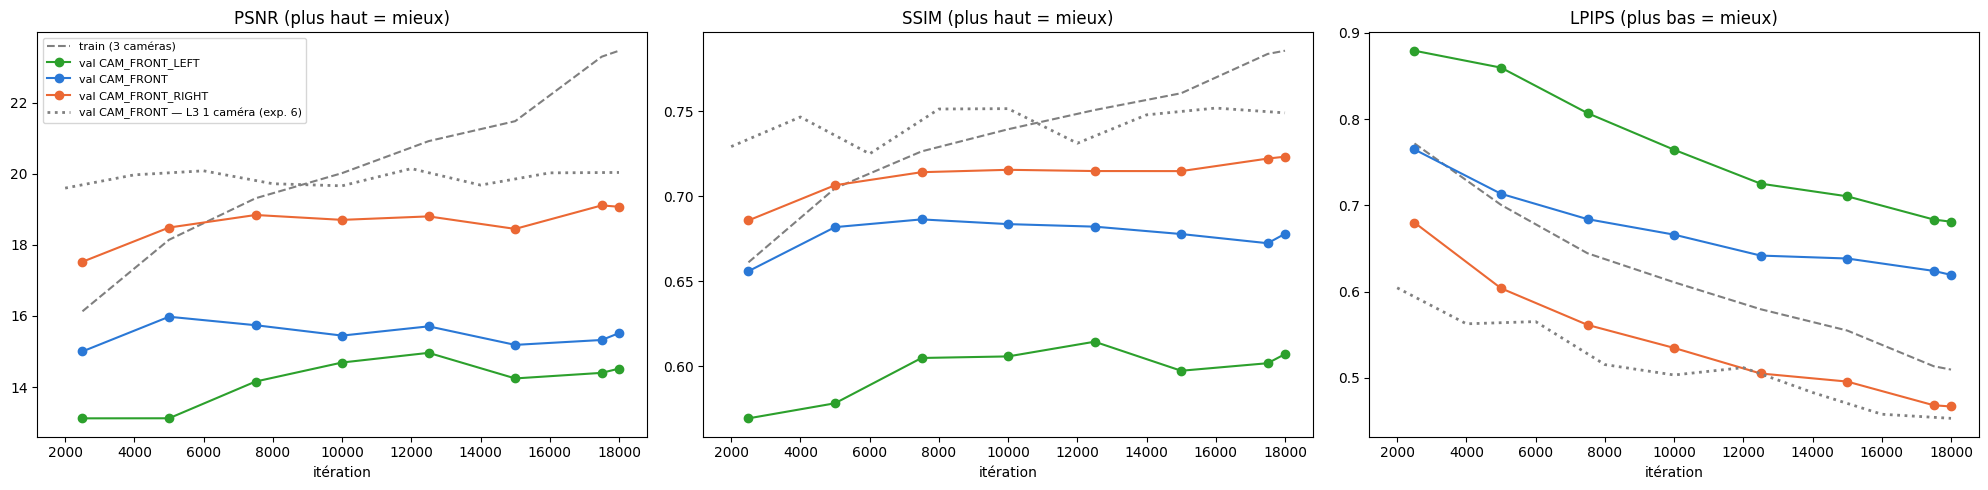

meilleur checkpoint (LPIPS val) : 17999 | 670614 gaussiennes


In [86]:
# --- Val par caméra, train, et référence : L3 à 1 caméra (exp. 6, val CAM_FRONT) ---
import json
import matplotlib.pyplot as plt

curves7 = json.load(open('/kaggle/working/exp7_curves.json'))
ref = json.load(open('/kaggle/working/exp6_curves.json'))['L3']
steps = [r['step'] for r in curves7]
colors = {'CAM_FRONT_LEFT': '#2ca02c', 'CAM_FRONT': '#2a78d6', 'CAM_FRONT_RIGHT': '#eb6834'}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, m in zip(axes, ['psnr', 'ssim', 'lpips']):
    ax.plot(steps, [r[f'train_{m}'] for r in curves7], '--', c='black', alpha=0.5, label='train (3 caméras)')
    for cam, c in colors.items():
        ax.plot(steps, [r[f'val_{m}_{cam}'] for r in curves7], '-o', c=c, label=f'val {cam}')
    ax.plot([r['step'] for r in ref], [r[f'val_{m}'] for r in ref], ':', c='gray', lw=2,
            label='val CAM_FRONT — L3 1 caméra (exp. 6)')
    ax.set_title(m.upper() + (' (plus bas = mieux)' if m == 'lpips' else ' (plus haut = mieux)'))
    ax.set_xlabel('itération')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig('/kaggle/working/exp7_curves.png', dpi=120)
plt.show()

best7 = min(curves7, key=lambda r: r['val_lpips'])
print('meilleur checkpoint (LPIPS val) :', best7['step'], '|', best7['n_gaussians'], 'gaussiennes')